## Extracted Samples

In [46]:
#####################################################
# Find first sample extracted when 5M threshold 
# - Should be 'Heart'
# - Check if the min and the 1st sample are the same 
#####################################################
import h5py
import pickle

pickle_in = open("/home/lwu/ARCHS4/Tests/5M Threshold Sample Retention Plots/5M_threshold_sample_idxs_list.pkl", 'rb')
threshold_sample_idx = pickle.load(pickle_in)
pickle_in.close()

print("# Samples Above Threshold:", len(threshold_sample_idx))
print("ST - 192k:", max(threshold_sample_idx))
print("ST - 0?:", min(threshold_sample_idx))
print("ST - 0?:", threshold_sample_idx[0])
print()

# ---------------------------------------------------------------------------------------------------------- #                                                                 
# Get extracted sample names from the 5M threshold 
# - Get first extracted sample 
#####################################################
                                       
print("SAMPLE NAMES [192K]")
print("*******************")

root = "/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/sbatch_files/makefiles/"
with h5py.File(root + 'extracted_corrected_threshold_qn_matrixs_LW20230126.h5', 'r') as f:
    sample_names = f['sample_names'][:]
    print("*1st 5M Extracted Sample Name:", sample_names[threshold_sample_idx[0]])
print()
    
threshold_sample_names = [sample_names[i] for i in threshold_sample_idx]
print("Genes (~85k):", len(threshold_sample_names))
print("*Check if same:", threshold_sample_names[0])
    

# Samples Above Threshold: 87875
ST - 192k: 192600
ST - 0?: 82
ST - 0?: 82

SAMPLE NAMES [192K]
*******************
*1st 5M Extracted Sample Name: b'Heart'

Genes (~85k): 87875
*Check if same: b'Heart'


In [93]:
# Get 5 sample names
selected_samples_idxs = [82, 5360, 145828, 167735, 192600]
selected_samples_names = [sample_names[i] for i in selected_samples_idxs]
selected_samples_names = [x.decode('UTF-8') for x in selected_samples_names]
print("Selected Samples:",selected_samples_names)

Selected Samples: ['Heart', 'Human adipose-derived mesenchymal stem cells', 'A549-ACE2 plus Amlodipine and SARS-CoV-2', 'MDA-MB-231 siCt', 'Human Testis Biopsy']


In [96]:
# Get QN Matrix Idxs

qn_selected_indexes = [i for i, x in enumerate(threshold_sample_idx) if x in selected_samples_idxs]
print(qn_selected_indexes)  


[0, 3366, 60637, 72946, 87874]


---
# Sample Top 100 Genes Scatterplot

In [143]:
def get_column_stats(mat):
    stats = []
    for col in mat.T:
        zeros = (col == 0).sum()
        nonzeros = (col != 0).sum()
        above_1 = (col > 1).sum()
        col_sum = col.sum()
        stats.append([zeros, nonzeros, above_1, col_sum])
    return stats

stats = get_column_stats(extracted_matrix)

print("Column statistics:")
for i, s in enumerate(stats):
    print(f"Column {i}: zeros={s[0]}, non-zeros={s[1]}, above 1={s[2]}, sum={s[3]}")

Column statistics:
Column 0: zeros=29030, non-zeros=28417, above 1=25197, sum=14662645
Column 1: zeros=33677, non-zeros=23770, above 1=20278, sum=20462537
Column 2: zeros=31192, non-zeros=26255, above 1=23672, sum=16179174
Column 3: zeros=26256, non-zeros=31191, above 1=27253, sum=45745006
Column 4: zeros=25462, non-zeros=31985, above 1=28843, sum=35930604


In [94]:
import h5py
import matplotlib.pyplot as plt
import numpy as np

# Extracted Matrix  
print("EXTRACTED MATRIX")
print("****************")

root = "/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/sbatch_files/makefiles/"
with h5py.File(root + 'extracted_corrected_threshold_qn_matrixs_LW20230126.h5', 'r') as f:
    extracted_matrix = f['matrix'][:, selected_samples_idxs]
    print("***Data Read***")
    
    
# Create the histogram
#plt.xlim(0, 60000)
#plt.plot(extracted_matrix)

EXTRACTED MATRIX
****************
***Data Read***


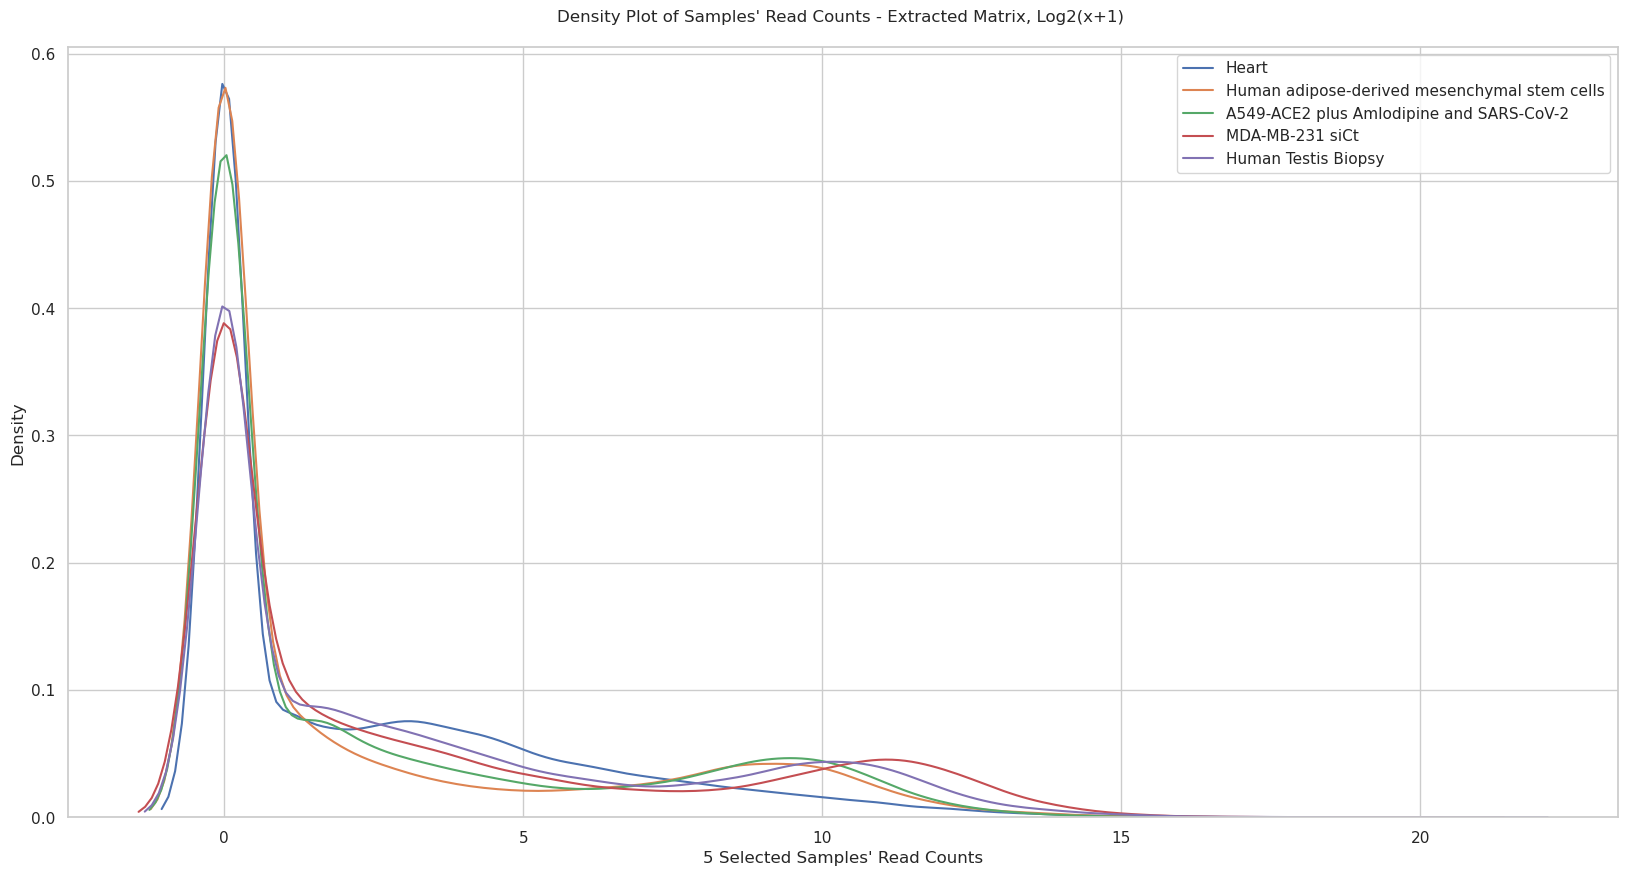

In [119]:
# PLOT

for i in range(len(extracted_matrix[0])):
    sns.kdeplot(np.log2(1+extracted_matrix[:, i]), label=selected_samples_names[i])
sns.set(rc={'figure.figsize':(20,10)})
sns.set(style="whitegrid")
plt.xlabel("5 Selected Samples' Read Counts")
plt.title("Density Plot of Samples' Read Counts - Extracted Matrix, Log2(x+1) \n")
plt.legend()


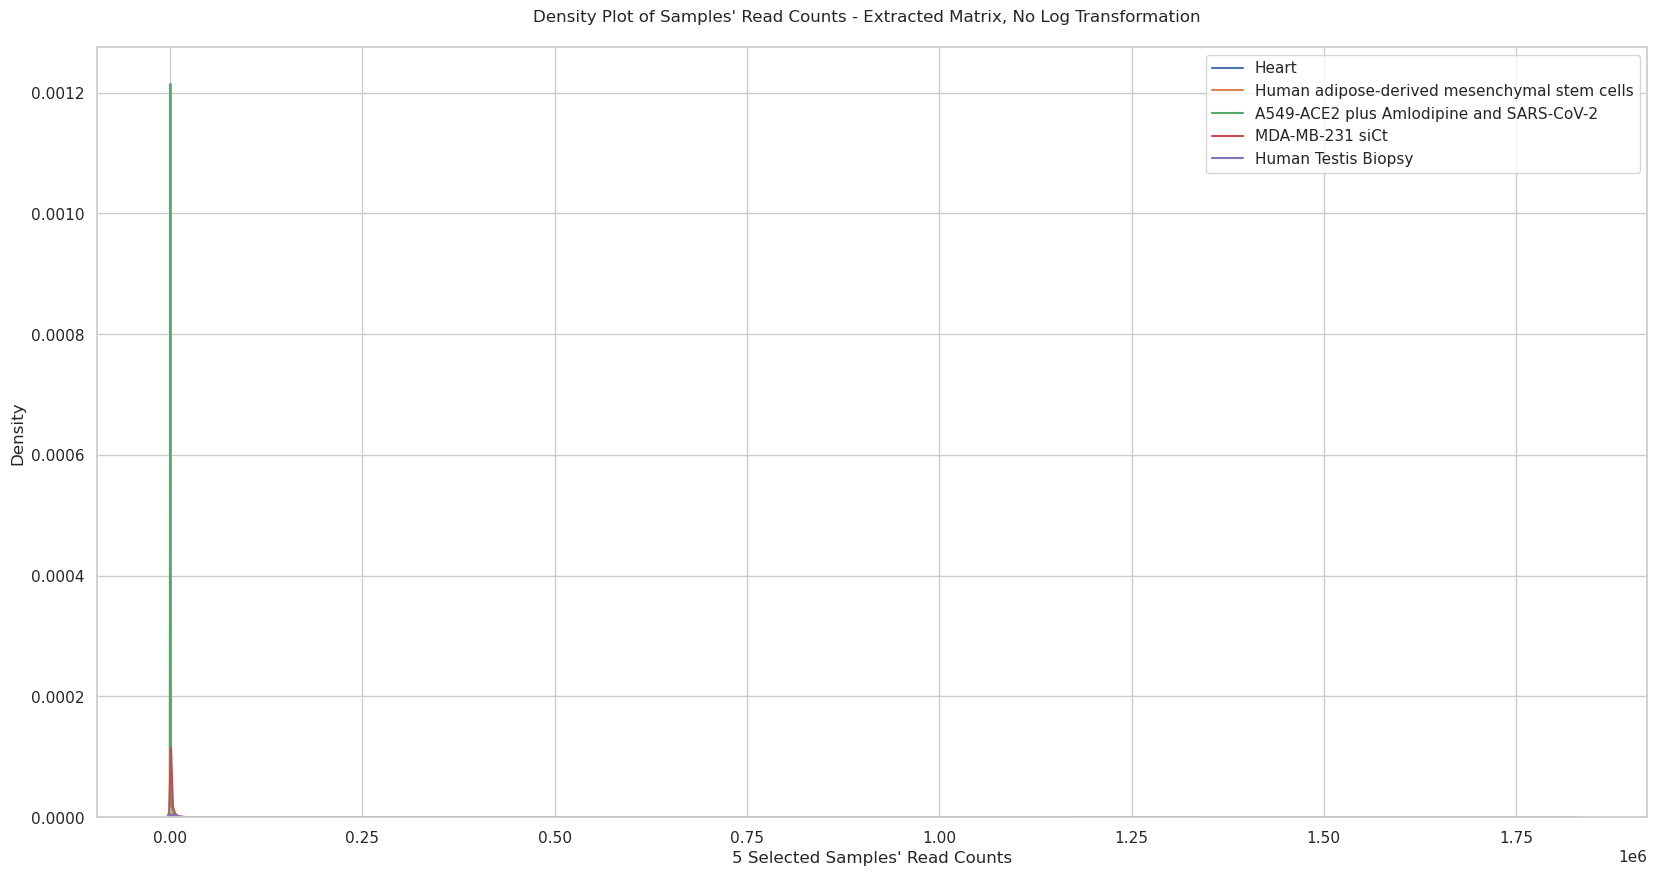

In [151]:
# PLOT

for i in range(len(extracted_matrix[0])):
    sns.kdeplot(extracted_matrix[:, i], label=selected_samples_names[i])
sns.set(rc={'figure.figsize':(20,10)})
sns.set(style="whitegrid")
plt.xlabel("5 Selected Samples' Read Counts")
plt.title("Density Plot of Samples' Read Counts - Extracted Matrix, No Log Transformation  \n")
plt.legend()


In [132]:
extracted_matrix.shape

(57447, 5)

Text(0.5, 1.0, "Density Plot of 'Heart' Sample Read Counts - Extracted Matrix\n")

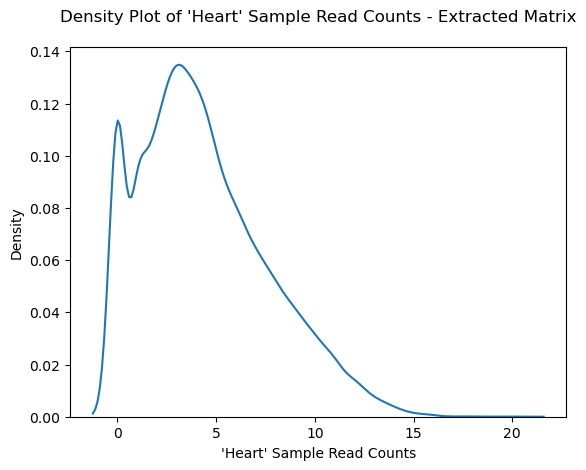

In [86]:
# /= Multiple Samples (Only 1)

np.seterr(divide = 'ignore') 
sns.kdeplot(np.log2(extracted_matrix))
plt.xlabel("'Heart' Sample Read Counts")
plt.title("Density Plot of 'Heart' Sample Read Counts - Extracted Matrix\n")

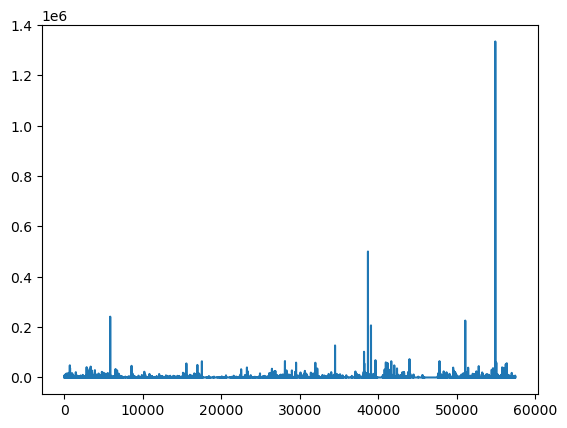

In [73]:
# /= Log2 Transformation 
plt.plot(extracted_matrix)

---
## Get Corrected Chosen 'Heart' Sample

CORRECTED MATRIX
****************
***Data Read***


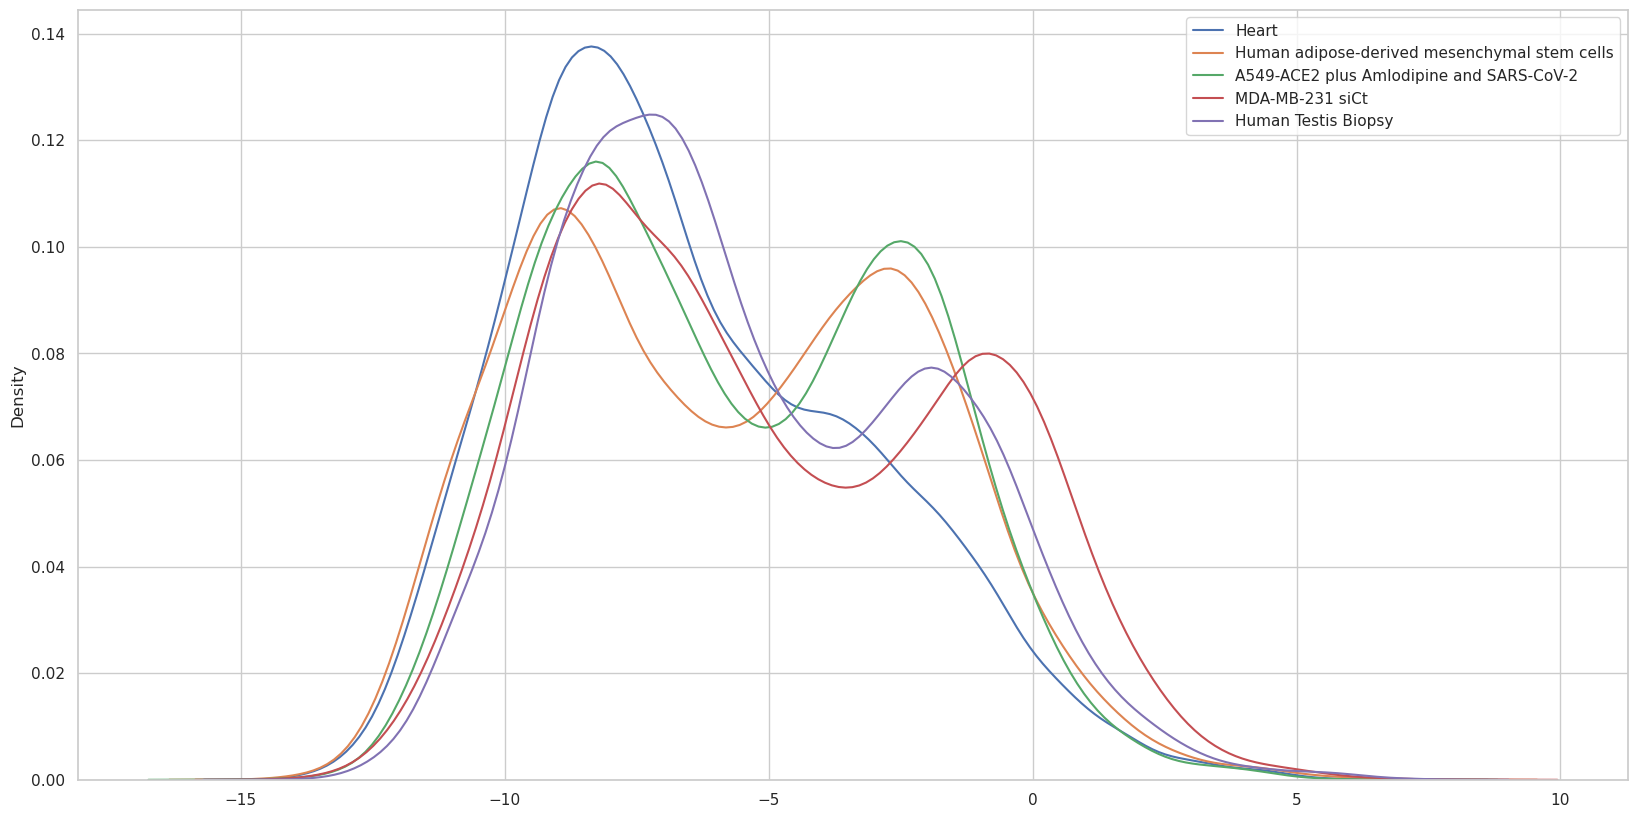

In [110]:
import h5py
import matplotlib.pyplot as plt

# QN Matrix  
print("CORRECTED MATRIX")
print("****************")

root = "/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/sbatch_files/makefiles/"
with h5py.File(root + 'extracted_corrected_threshold_qn_matrixs_LW20230126.h5', 'r') as f:
    corrected_matrix = f['corrected_matrix'][:, selected_samples_idxs]
    print("***Data Read***")

# PLOT
for i in range(len(corrected_matrix[0])):
    sns.kdeplot(np.log2(corrected_matrix[:, i]), label=selected_samples_names[i])
sns.set(rc={'figure.figsize':(20,10)})
sns.set(style="whitegrid")
plt.xlabel("5 Selected Samples' Read Counts")
plt.title("Density Plot of Samples' Read Counts - Corrected Matrix\n")
plt.legend()

    
# Create the histogram
#plt.plot(corrected_matrix)


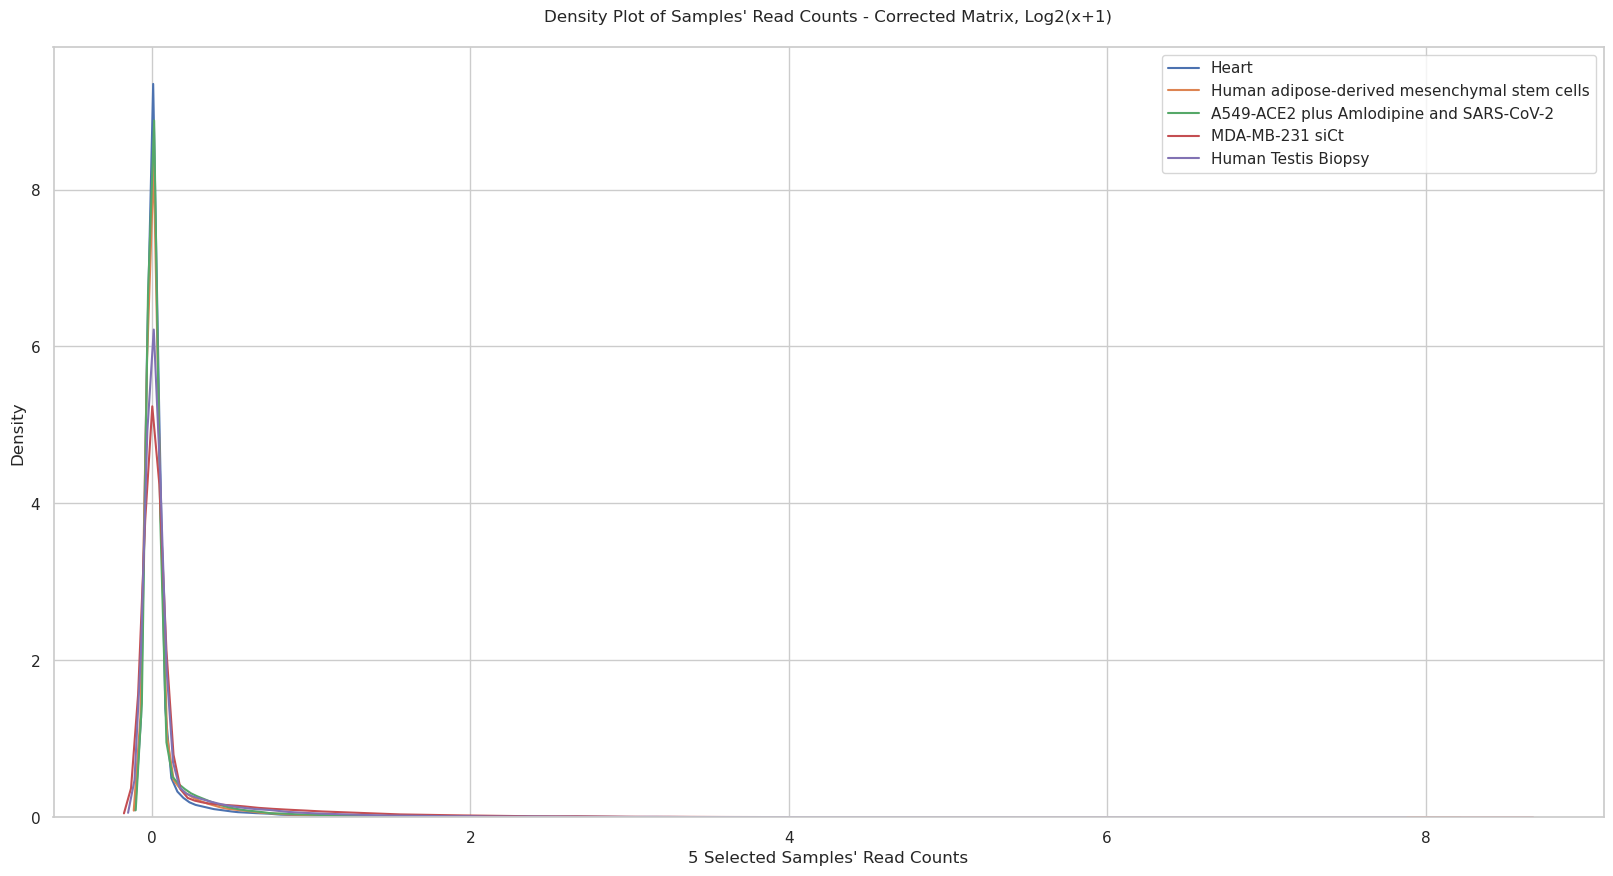

In [124]:
# PLOT
for i in range(len(corrected_matrix[0])):
    sns.kdeplot(np.log2(1+corrected_matrix[:, i]), label=selected_samples_names[i])
sns.set(rc={'figure.figsize':(20,10)})
sns.set(style="whitegrid")
plt.xlabel("5 Selected Samples' Read Counts")
plt.title("Density Plot of Samples' Read Counts - Corrected Matrix, Log2(x+1)\n")
plt.legend()


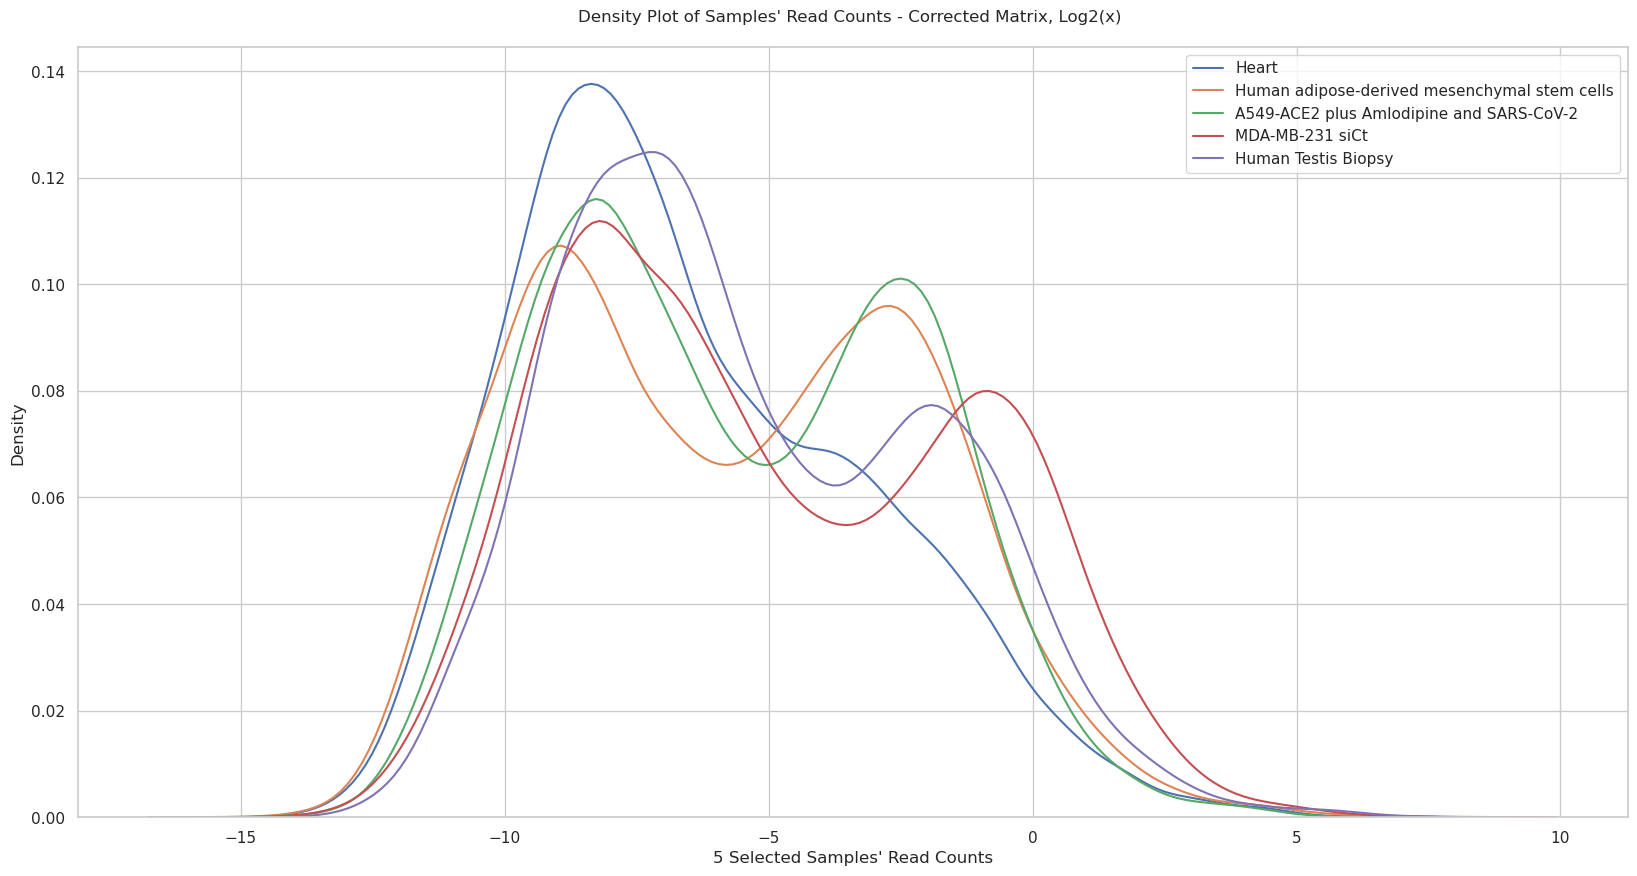

In [125]:
# PLOT
for i in range(len(corrected_matrix[0])):
    sns.kdeplot(np.log2(corrected_matrix[:, i]), label=selected_samples_names[i])
sns.set(rc={'figure.figsize':(20,10)})
sns.set(style="whitegrid")
plt.xlabel("5 Selected Samples' Read Counts")
plt.title("Density Plot of Samples' Read Counts - Corrected Matrix, Log2(x) \n")
plt.legend()


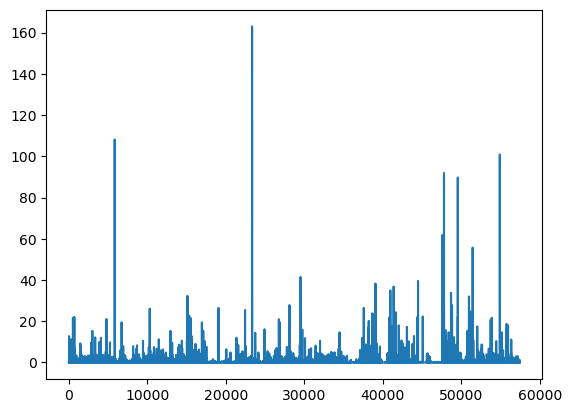

In [60]:
# Create the histogram
plt.plot(corrected_matrix)

Text(0.5, 1.0, "Density Plot of 'Heart' Sample Read Counts - Gene Corrected Matrix\n")

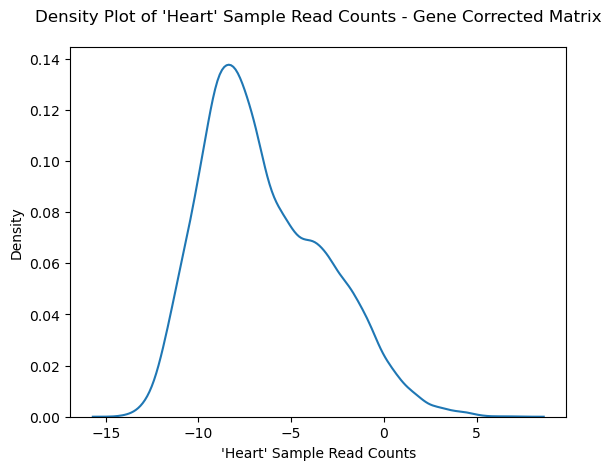

In [87]:
sns.kdeplot(np.log2(corrected_matrix))
plt.xlabel("'Heart' Sample Read Counts")
plt.title("Density Plot of 'Heart' Sample Read Counts - Gene Corrected Matrix\n")

---
## Get QN Chosen 'Heart' Sample

QN MATRIX
****************
***Data Read***


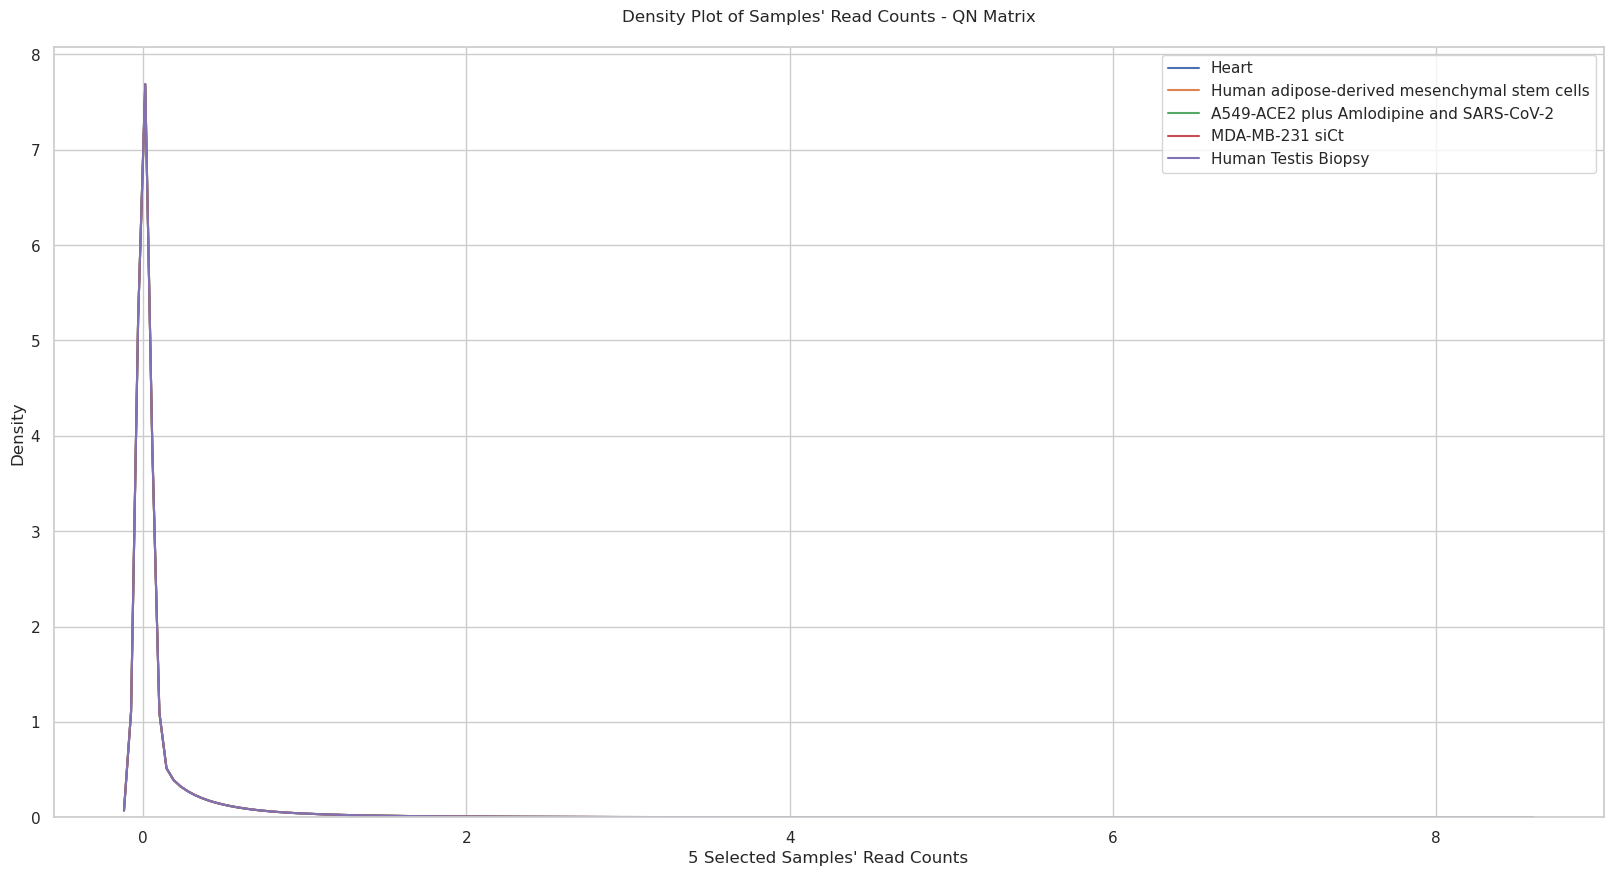

In [114]:
import h5py
import matplotlib.pyplot as plt

# QN Matrix  
print("QN MATRIX")
print("****************")

root = "/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/sbatch_files/makefiles/"
with h5py.File(root + 'extracted_corrected_threshold_qn_matrixs_LW20230126.h5', 'r') as f:
    qn_matrix = f['qn_matrix'][:, qn_selected_indexes]
    print("***Data Read***")

# PLOT
for i in range(len(qn_matrix[0])):
    sns.kdeplot(qn_matrix[:, i], label=selected_samples_names[i])
sns.set(rc={'figure.figsize':(20,10)})
sns.set(style="whitegrid")
plt.xlabel("5 Selected Samples' Read Counts")
plt.title("Density Plot of Samples' Read Counts - QN Matrix)\n")
plt.legend()

# Create the histogram
#plt.plot(qn_matrix)


Text(0.5, 1.0, "Density Plot of 'Heart' Sample Read Counts - QN Matrix\n")

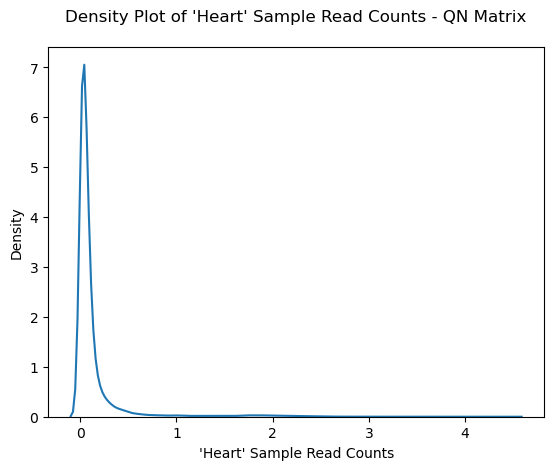

In [89]:
sns.kdeplot(qn_matrix)
plt.xlabel("'Heart' Sample Read Counts")
plt.title("Density Plot of 'Heart' Sample Read Counts - QN Matrix\n")

# TEST

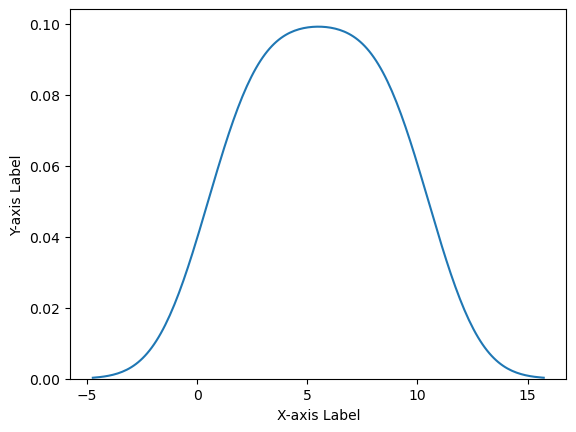

In [77]:
#%pip install seaborn
import seaborn as sns
import matplotlib.pyplot as plt

# Test data
data = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

sns.kdeplot(data)
plt.xlabel("X-axis Label")
plt.ylabel("Y-axis Label")
plt.show()
